In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import plutocode

Se busca minimizar la suma de los cuadrados de los errores para un ajuste exponencial $Ae^{\lambda x}. Para esto es necesario solucionar el sistema:

\begin{align*}
    &A = \frac{\sum_{i=1}^{n} y_i e^{\lambda x_1}}{\sum_{i=1}^{n} e^{2\lambda x_i}} \\[10pt]

    &\sum_{i=1}^{n} x_i y_i e^{\lambda x_i} - A \sum_{i=1}^{n} x_i e^{2\lambda x_i} = 0
\end{align*}

Reemplazando $A$ en la segunda expresión, será posible obtener la solución al hallar $\lambda$ como la raíz de esta, y $A$ al reemplazar este valor.

A:
  Para el ajuste exponencial realizado: A = 0.99985,  lambda = -0.00896. 
  L/L0 = 0.99985 * exp(-0.00896*t).
B:
  La vida media es: tau = -77.40023 días.
C:
 El flujo relativo a los 100 días es de: 0.40833.


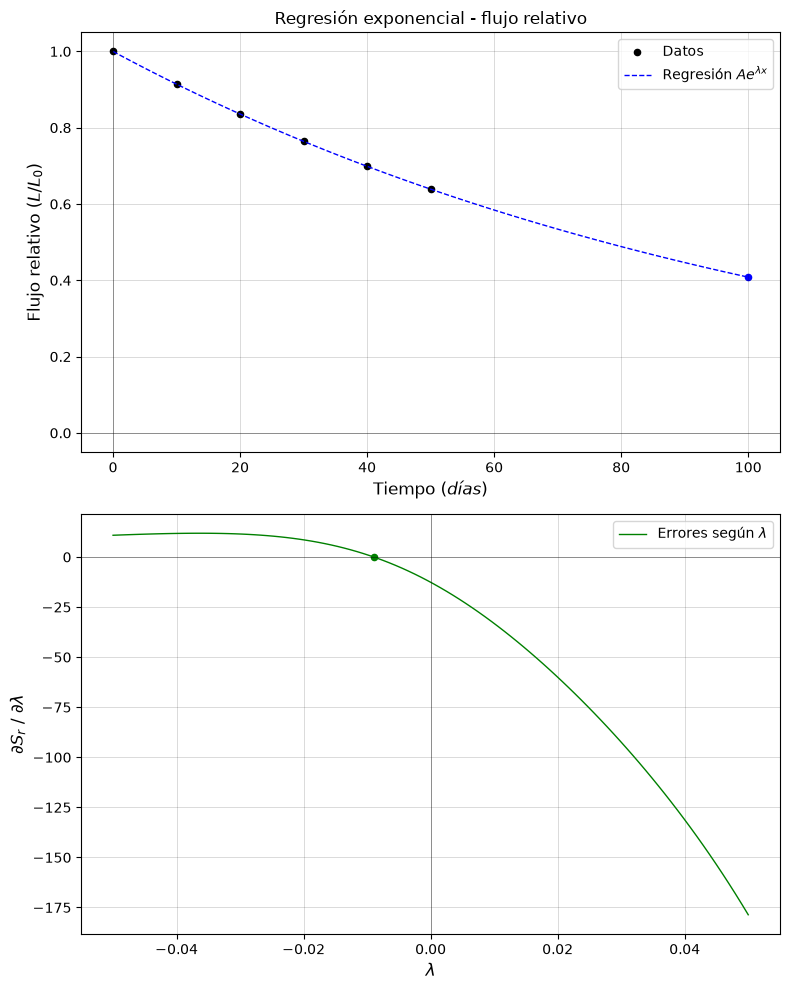

In [45]:
# REGRESIÓN EXPONENCIAL SIN REEMPLAZO LINEAL

time = np.linspace(0, 50, 6)
flux = np.array([1.0, 0.914, 0.836, 0.764, 0.699, 0.639])

# ------------- Método de la Secante para raíces -------------

def leastsquares_exp(b):

   x = time
   y = flux

   a = np.sum(y * np.exp(b*x))/np.sum(np.exp(2*b*x))

   return np.sum(x * y * np.exp(b*x)) - a * np.sum(x * np.exp(2*b*x)), a 

# ------------- Estimación inicial de lambda -------------

b_start = [-5e-2, 0]

# ------------- Implementación del método -------------

def secante(x_start, f, m):

    counter = 0
    scarborough = 0.5 * 10**(2-m)
    eps = float('inf')

    x_prev, x_current = x_start[0], x_start[1]

    while eps > scarborough:

        x_next = x_current - f(x_current)[0]*(x_current - x_prev)/(f(x_current)[0] - f(x_prev)[0])
        eps = 100 * abs((x_next - x_current)/x_next)

        x_prev = x_current
        x_current = x_next
        counter += 1

    return x_current, counter, eps

# ------------- Solución parámetros de regresión -------------

lambd, counter, eps = secante(b_start, leastsquares_exp, m=3)
err, A = leastsquares_exp(lambd)

print(f"A:\n  Para el ajuste exponencial realizado: A = {A:.5f},  lambda = {lambd:.5f}. \n  L/L0 = {A:.5f} * exp({lambd:.5f}*t).")

# ------------- Vida media -------------

t_half = np.log(2)/lambd

print(f"B:\n  La vida media es: tau = {t_half:.5f} días.")

# ------------- Flujo relativo -------------

flux100 = A*np.exp(lambd*100)

print(f"C:\n El flujo relativo a los 100 días es de: {flux100:.5f}.")

# ------------- Graficación -------------

time_arr = np.linspace(0, 100, 100)
flux_arr = A*np.exp(lambd*time_arr)
b_arr = np.linspace(-0.05,0.05, 100)
fb_vals = [leastsquares_exp(b)[0] for b in b_arr]

fig, (ax1,ax2) = plt.subplots(2, 1, figsize=(8, 10))

ax1.scatter(time, flux, color='k', s=20, label='Datos')
ax1.plot(time_arr, flux_arr, 'b--', lw=1, label=r'Regresión $Ae^{\lambda x}$')
ax1.scatter(100, flux100, color='b', s=20, marker='o')

ax1.grid(color='k', lw=0.5, alpha=0.2)
ax1.axhline(y=0, color='k', lw=0.5, alpha=0.5)
ax1.axvline(x=0, color='k', lw=0.5, alpha=0.5)
ax1.set_xlabel('Tiempo ($días$)', fontsize=12)
ax1.set_ylabel('Flujo relativo ($L/L_0$)', fontsize=12)
ax1.set_title('Regresión exponencial - flujo relativo', fontsize=12)
ax1.legend()

ax2.plot(b_arr, fb_vals, color='g', lw=1, label=r'Errores según $\lambda$')
ax2.scatter(lambd, err, color='g', s=20)

ax2.grid(color='k', lw=0.5, alpha=0.2)
ax2.axhline(y=0, color='k', lw=0.5, alpha=0.5)
ax2.axvline(x=0, color='k', lw=0.5, alpha=0.5)
ax2.set_xlabel(r'$\lambda$', fontsize=12)
ax2.set_ylabel(r'$\partial S_r ~/~ \partial \lambda$', fontsize=12)
ax2.legend()

plt.tight_layout()
plt.show()
